# 03 · Phase 3: Physics-informed features (F4)

**Goal (RQ3, part 1).** Find features tied to degradation mechanisms that add information **beyond ΔQ(V)**.
Quality over quantity: with 41 training cells, every weak feature is a chance to overfit.

**Rules used for every candidate (training cells only; the test sets are used once, in §7, after F4 is fixed):**
1. a physical mechanism behind it;
2. it must add information beyond `dq_log_var` (within-batch t-statistic, paired cross-validated gain);
3. the same sign **within** b1 and within b2, otherwise it is a batch proxy;
4. it must still help on top of a plain batch label;
5. it must be measurable above the noise in cycles ≤ 100.

**Prerequisite** (repo root, ~4 min, reads raw traces for temperatures and protocol steps):
```
python3 -m src.features && python3 -m src.screen_physics && python3 -m src.p3_evaluate
```

| § | Content |
|---|---|
| 1 | The screening table: 19 candidates |
| 2 | Why mechanism features fail: ΔQ already contains them |
| 3 | Batch traps: curvature (Simpson's paradox), temperature, rest time |
| 4 | ΔQ grows linearly → the **margin / rate** feature |
| 5 | The overhang effect → the **overhang_after10** feature |
| 6 | Final F4 vs the paper's sets (nested CV on training cells) |
| 7 | Test performance with the paper's model (F4 frozen) |
| 8 | Caveats and what Phase 4 must test |

Tags: **[paper]** Severson et al., **[data]** measured here, **[hypothesis]** interpretation.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, LogNorm
import statsmodels.api as sm
from config import VDLIN, RESULTS_DIR
from src.data import load_dataset, curve
from src.features import load_features, FEATURE_SETS, PHYSICS_FEATURES

%matplotlib inline
mpl.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.color": "#e4e3df", "axes.axisbelow": True,
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False, "font.size": 9})
C1, C2, INK2 = "#2a78d6", "#eb6834", "#52514e"
BSTYLE = {"b1": (C1, "o"), "b2": (C2, "s")}
BLUES = LinearSegmentedColormap.from_list("blues", ["#b7d3f6", "#6da7ec", "#2a78d6", "#1c5cab", "#104281", "#0d366b"])
pd.set_option("display.width", 180, "display.max_columns", 30)

cells = load_dataset()["cells"]
df = load_features()
tr = df[df.split == "train"]                       # Phase 3 only ever looks at these 41 cells' lives
y = np.log10(tr.cycle_life.to_numpy())
S = json.load(open(RESULTS_DIR / "p3_screening.json"))
C = pd.read_csv(RESULTS_DIR / "p3_candidates_train.csv", index_col=0)
print(f"{len(tr)} training cells (b1 {sum(tr.batch == 'b1')}, b2 {sum(tr.batch == 'b2')})")

41 training cells (b1 20, b2 21)


## 1 · The screening table
Columns: Spearman ρ with log life (all / within b1 / within b2); t-statistic of the candidate **given `dq_log_var`**
within each batch; paired cross-validated gain (%) on top of `dq_log_var`, on top of `margin_rate`, and on top of
`dq_log_var` + batch label. Positive gain = lower error.

In [2]:
T = pd.DataFrame({k: v for k, v in S["candidates"].items() if not k.startswith("_")}).T
cols = ["mechanism", "rho_all", "rho_b1", "rho_b2", "t_given_dq_b1", "t_given_dq_b2",
        "gain_on_dq_pct", "gain_on_margin_pct", "gain_beyond_batch_pct", "selected"]
T = T[cols]
for c in cols[1:-1]:
    T[c] = T[c].astype(float).round(2)
print("reference:", {k: round(v, 4) for k, v in S["candidates"]["_reference"].items()})
T.sort_values("gain_on_dq_pct", ascending=False)

reference: {'cv_rmse_log_dq_log_var': 0.0714, 'cv_rmse_log_margin_rate': 0.065, 'margin_better_than_dq_folds_pct': 96.0, 'cv_rmse_log_dq_plus_batch': 0.0501}


,mechanism,rho_all,rho_b1,rho_b2,t_given_dq_b1,t_given_dq_b2,gain_on_dq_pct,gain_on_margin_pct,gain_beyond_batch_pct,selected
overhang_after10,overhang hiding ΔQ,-0.06,0.42,0.07,-3.89,-1.60,25.68,22.90,11.18,True
t_cycle,time-based ageing (protocol),-0.69,0.54,-0.00,0.56,-0.74,24.77,21.64,2.16,False
t_half_rise,overhang timing,-0.03,0.32,0.02,-2.95,-2.28,17.50,16.63,13.70,False
margin_rate,budget / rate,0.83,0.84,0.51,5.30,0.05,9.58,0.00,-0.29,True
peak_cycle,overhang timing,0.20,0.40,0.08,-2.25,-2.07,7.01,8.67,16.78,False
rise_before10,overhang,0.20,0.46,0.15,-2.55,-0.74,6.40,8.41,3.10,False
T_start_fastcharge,plating vs temperature,0.54,-0.32,0.19,-0.40,2.02,4.41,3.41,-1.96,False
traj_exponent,fade acceleration,-0.39,-0.23,0.00,-1.36,0.60,-0.69,-0.83,1.90,False
ir_sqrt_slope,SEI growth ~ sqrt(t),0.30,-0.39,-0.10,1.82,-2.79,-1.43,-3.24,2.69,False
temp_rise_mean,Joule heating,-0.21,-0.32,-0.01,-1.22,0.75,-1.63,-1.24,-1.20,False


**Reading the table**
* The mechanism features (dQ/dV peaks, CV hold, ΔQ offset, IR slope, heating, coulombic efficiency) all have
  **negative** gain on top of ΔQ: their information is already in it (§2).
* `qd_curv_2_100`, `T_start_fastcharge`, `plating_index`, `t_cycle` look good overall but change sign or vanish
  within a batch: batch proxies (§3).
* Only the overhang-timing family and `margin_rate` survive (§4–5).
* Coulombic efficiency cannot be measured here: the median of QD/QC is slightly **above** 1 [data].

## 2 · Why mechanism features fail: ΔQ already contains them
ΔQ(V) is the combined fingerprint of loss of active material, loss of lithium and kinetics. A feature that re-measures
one of these from the same discharge curves adds little.

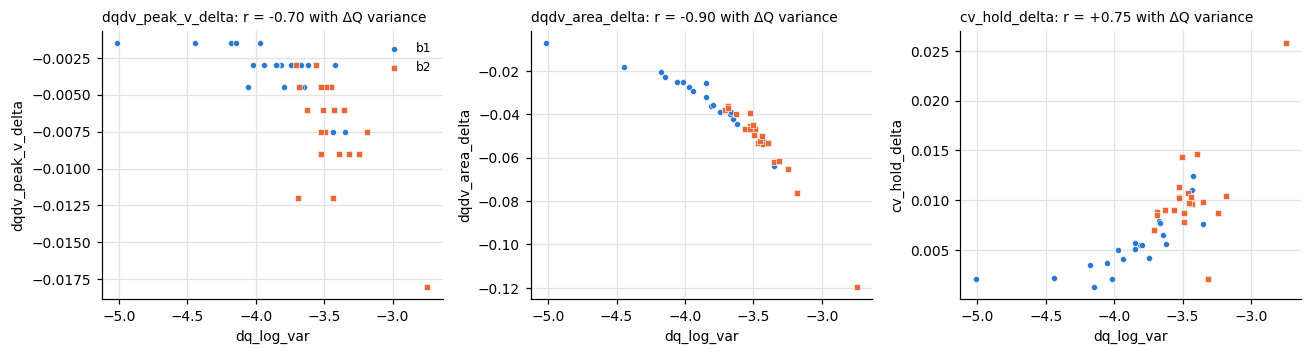

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.3))
for ax, k in zip(axes, ["dqdv_peak_v_delta", "dqdv_area_delta", "cv_hold_delta"]):
    for b, (col, mk) in BSTYLE.items():
        m = (tr.batch == b).to_numpy()
        ax.scatter(tr.dq_log_var[m], C[k][m], color=col, marker=mk, s=16, edgecolor="white", lw=0.4, label=b)
    r = np.corrcoef(tr.dq_log_var, C[k])[0, 1]
    ax.set(xlabel="dq_log_var", ylabel=k); ax.set_title(f"{k}: r = {r:+.2f} with ΔQ variance", loc="left", fontsize=9)
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

## 3 · Batch traps
### 3a · Curvature of the capacity fade: Simpson's paradox
Over cycles 2–100, capacity first **rises** (overhang) and then falls. In long-lived b1 the curvature mostly measures
the rise; in b2 several cells already fade. The sign of the relation flips between batches; pooled, it just
separates b1 from b2.

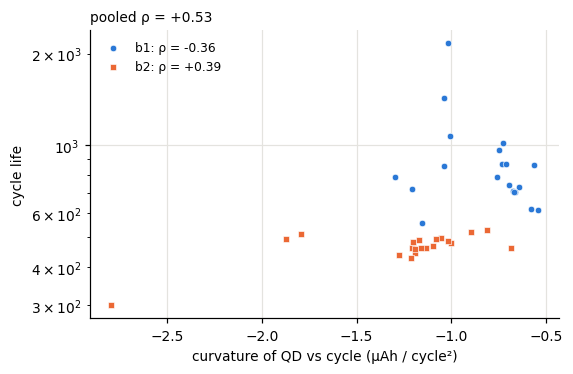

In [4]:
fig, ax = plt.subplots(figsize=(5.5, 3.4))
for b, (col, mk) in BSTYLE.items():
    m = (tr.batch == b).to_numpy()
    x = 1e6 * C.qd_curv_2_100[m]; yy = tr.cycle_life[m]
    ax.scatter(x, yy, color=col, marker=mk, s=18, edgecolor="white", lw=0.4, label=f"{b}: ρ = {S['candidates']['qd_curv_2_100']['rho_' + b]:+.2f}")
ax.set_yscale("log"); ax.set(xlabel="curvature of QD vs cycle (µAh / cycle²)", ylabel="cycle life")
ax.set_title(f"pooled ρ = {S['candidates']['qd_curv_2_100']['rho_all']:+.2f}", loc="left", fontsize=9); ax.legend(fontsize=8)
plt.show()

### 3b · Protocol: rest time and temperature
The temperature integral of the paper's full model is 92% cycle duration. The step breakdown below (random cells of
every group, protocol and temperature only, no lives) shows where the time goes: `-newstructure` means 5-second rests
(as in b3 [paper]); b2 and u1-standard rest ~10 min per cycle; u1-standard also holds 3.6 V for ~20 min.

In [5]:
pd.DataFrame(S["steps"]).T.round(1)

,fast_charge,rest_after_80pct,cc_1C,cv_3.6V,discharge_cc_4C,discharge_cv_2V,rest_after_discharge,total,T_start_fastcharge
b1,11.0,1.0,9.4,10.5,14.6,5.4,0.0,52.0,32.5
b2,10.1,5.0,9.0,10.9,14.5,5.5,4.9,60.0,31.3
b3,10.0,0.2,8.9,7.9,14.4,3.8,0.1,45.6,35.2
u1,10.1,4.9,8.3,19.7,14.6,7.8,4.9,69.8,31.3
u1-newstructure,10.0,0.2,9.0,8.8,14.4,4.6,0.2,47.5,33.8


Rest time and the temperature at the start of the fast charge line up with the batches' typical lives, and a warmer
cell is less prone to lithium plating [hypothesis]. But **within** a batch neither helps
(`T_start_fastcharge`: t given ΔQ = −0.4 in b1, +2.0 in b2; gain beyond a batch label −2%), and rest time is constant within
a training batch, so it cannot be separated from "b1 vs b2". Both are kept as hypotheses for the unseen-batch analysis
(Phase 5), not as features.

## 4 · ΔQ grows linearly → margin / rate
The amplitude (standard deviation) of ΔQₙ₋₁₀ at n = 20, 30, …, 100 follows a power law with exponent **p ≈ 1**: the
curve-shape change grows at a **constant rate** over the first 100 cycles. The paper hypothesised linear LAM
degradation [paper]; the trajectories show it directly [data]. The knee is therefore a threshold event that cannot be
seen as acceleration in early data, so fitting a per-cell exponent only adds noise (`traj_exponent`, `qd_curv`).

median exponent 1.01 (IQR 0.98–1.11); median fit R² 0.986
median amplitude (mAh) at cycles {20: 1.73, 30: 2.97, 40: 4.69, 50: 6.71, 60: 9.0, 70: 10.25, 80: 12.45, 90: 13.81, 100: 15.5}


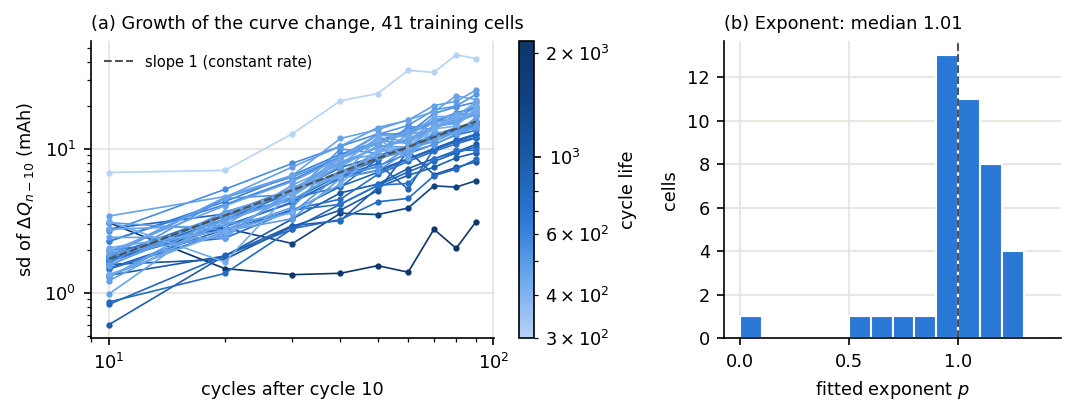

In [6]:
tj = S["trajectory"]
print(f"median exponent {tj['median_exponent']:.2f} (IQR {tj['q25']:.2f}–{tj['q75']:.2f}); median fit R² {tj['median_r2']:.3f}")
print("median amplitude (mAh) at cycles", dict(zip(tj["cycles"], tj["median_amp_mAh"])))
from IPython.display import Image
Image(str(ROOT / "report" / "figures" / "fig_p3_traj.png"), width=760)

With a constant rate, life ≈ **budget / rate**. End of life is an absolute threshold (0.88 Ah), so the budget is
QD(2) − 0.88 Ah, and the rate is the ΔQ amplitude:

$$\texttt{margin\_rate} = \log_{10}\frac{Q_{D,2} - 0.88}{\mathrm{sd}(\Delta Q_{100-10})}$$

Nothing is fitted inside the feature. Its fitted slope against log life is 0.79 (physics: ≈ 1).

CV RMSE (log10 life): dq_log_var 0.0714  vs  margin_rate 0.0650  -> margin_rate better in 96% of folds
within-batch t given dq_log_var: b1 +5.30, b2 +0.05; gain beyond dq + batch label -0.3%


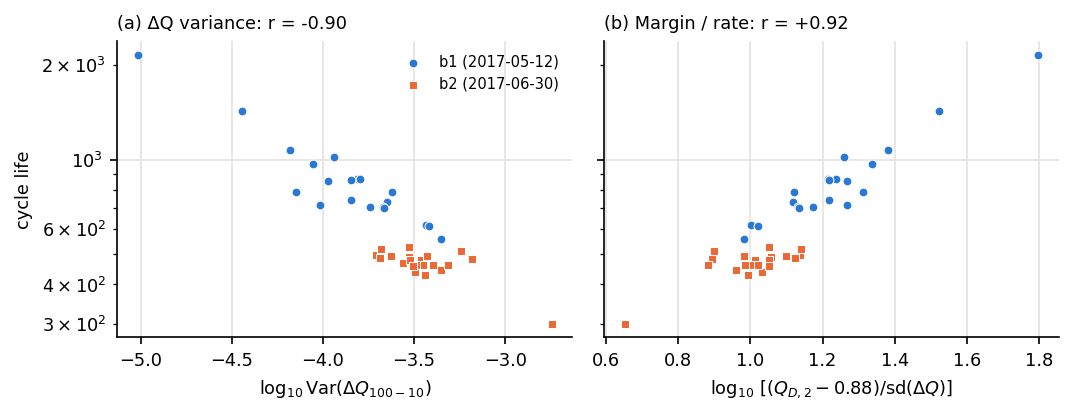

In [7]:
ref = S["candidates"]["_reference"]
print(f"CV RMSE (log10 life): dq_log_var {ref['cv_rmse_log_dq_log_var']:.4f}  vs  margin_rate {ref['cv_rmse_log_margin_rate']:.4f}"
      f"  -> margin_rate better in {ref['margin_better_than_dq_folds_pct']:.0f}% of folds")
mr = S["candidates"]["margin_rate"]
print(f"within-batch t given dq_log_var: b1 {mr['t_given_dq_b1']:+.2f}, b2 {mr['t_given_dq_b2']:+.2f};"
      f" gain beyond dq + batch label {mr['gain_beyond_batch_pct']:+.1f}%")
Image(str(ROOT / "report" / "figures" / "fig_p3_margin.png"), width=760)

**Caveat [data].** The margin form adds strong information within b1 (t = +5.3) but none within b2, whose lives span a
narrow range, and its pooled gain overlaps with the batch difference (b1 cells start ~6 mAh higher). It is kept because
it ranks cells better within **both** batches, and because the fixed physical form beats letting the model weight ΔQ and
QD(2) freely (§6).

## 5 · The overhang effect → overhang_after10
Most cells **gain** a few mAh early on: lithium parked in the anode overhang (the anode is larger than the cathode)
diffuses back and becomes cyclable [paper attributes the rise to the overhang]. The gain appears at the **low-voltage
end** of the discharge, and part of it comes out only in the 2.0 V CV hold, which `Qdlin` does not include.

If part of that release happens **inside** the ΔQ window (after cycle 10), it adds positive charge to ΔQ and partly
hides the degradation. Cells with a larger rise after cycle 10 should then live **shorter** than their ΔQ predicts.

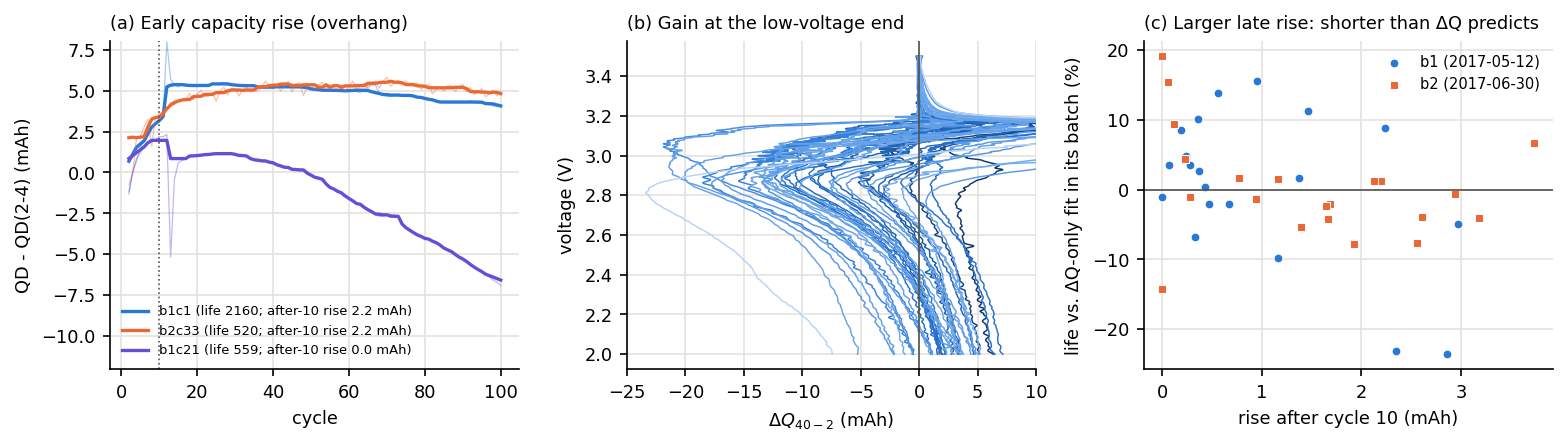

In [8]:
Image(str(ROOT / "report" / "figures" / "fig_p3_overhang.png"), width=980)

In [9]:
# the test of the explanation: rise before vs after cycle 10, within each batch, given ΔQ
rows = []
for f in ["rise_before10", "overhang_after10", "t_half_rise", "peak_cycle"]:
    c = S["candidates"][f]
    rows.append({"feature": f, "t_b1": c["t_given_dq_b1"], "p_b1": c["p_given_dq_b1"], "t_b2": c["t_given_dq_b2"],
                 "p_b2": c["p_given_dq_b2"], "gain_on_dq_%": c["gain_on_dq_pct"], "beyond_batch_%": c["gain_beyond_batch_pct"]})
pd.DataFrame(rows).set_index("feature").round(3)

,t_b1,p_b1,t_b2,p_b2,gain_on_dq_%,beyond_batch_%
feature,,,,,,
rise_before10,-2.548,0.021,-0.745,0.466,6.400,3.101
overhang_after10,-3.893,0.001,-1.595,0.128,25.681,11.183
t_half_rise,-2.950,0.009,-2.277,0.035,17.501,13.701
peak_cycle,-2.254,0.038,-2.068,0.053,7.008,16.777


The rise **after** cycle 10 carries far more information than the rise before it, as the explanation predicts
[data; the mechanism is a hypothesis]. Two robustness checks done during selection:
* the result holds for smoothing windows of 5, 9 and 15 cycles (b1 t between −2.9 and −3.2); the half-rise time does not;
* 7 of the 20 b1 training cells had a test pause at cycles 12–13. The capacity **step** across the pause carries no
  information (t = −0.1), while the gradual rise after cycle 15 still does (t = −2.2), so the signal is not a pause artefact.

## 6 · Final F4 vs the paper's feature sets
Nested cross-validation on the training cells with the paper's protocol (elastic net, inner RepeatedKFold(4, 10)),
outer RepeatedKFold(4, 10); the same 40 cells (temperature-probe cell `b1c3` left out) for every set.

,features,RMSE log10,RMSE cycles,better than F2 (% folds)
F1 variance,1.0,0.0708,107.5991,22.5
F2 discharge,6.0,0.0581,93.6100,0.0
F3 full,9.0,0.0510,88.8958,72.5
F4 physics,2.0,0.0509,77.0276,77.5
F3 + physics,11.0,0.0514,89.6639,70.0


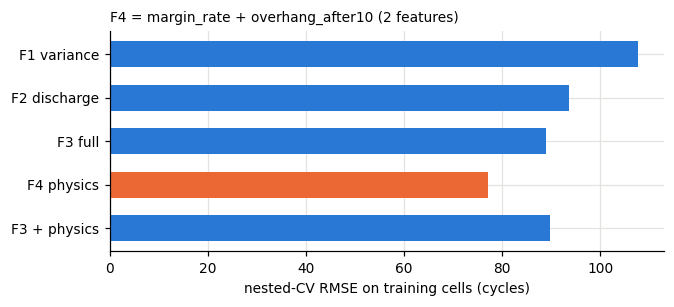

F4 = ['margin_rate', 'overhang_after10']


In [10]:
fs = S["feature_sets"]["sets"]
t = pd.DataFrame({k: {"features": v["n_features"], "RMSE log10": v["rmse_log"], "RMSE cycles": v["rmse_cycles"],
                      "better than F2 (% folds)": v["better_than_F2_folds_pct"]} for k, v in fs.items()}).T
display(t.round(4))
fig, ax = plt.subplots(figsize=(6.5, 2.6))
ax.barh(list(fs), [v["rmse_cycles"] for v in fs.values()], color=[C2 if k == "F4 physics" else C1 for k in fs], height=0.6)
ax.invert_yaxis(); ax.set_xlabel("nested-CV RMSE on training cells (cycles)")
ax.set_title("F4 = margin_rate + overhang_after10 (2 features)", loc="left", fontsize=9); plt.show()
print("F4 =", FEATURE_SETS["physics"])

Two features match the paper's nine on the log scale and do better in cycles, **without** the temperature integral,
charge time or IR, which are batch and policy proxies. Adding them to F3 does not help.

## 7 · Test performance with the paper's model
F4 was fixed above, before any test cell was used. It is evaluated **once** on the paper's splits with the paper's
protocol (`python3 -m src.p3_evaluate` → `results/p3_test_eval.json`) and is not changed afterwards.
Each entry: RMSE (cycles) / mean absolute % error.

In [11]:
E = json.load(open(RESULTS_DIR / "p3_test_eval.json"))
rows = {}
for name in ("variance", "discharge", "full", "physics", "full_physics"):
    m = E["models"][name]; sc = m["scores"]
    rows[name] = {"features": m["n_features"],
                  **{k: f"{sc[k]['rmse']:.0f} / {sc[k]['mape']:.1f}%" for k in ("train", "primary", "primary_excl", "secondary")},
                  "seed range (prim / sec)": ("–" if "seed_spread_rmse" not in m else
                      " / ".join(f"{a:.0f}–{b:.0f}" for a, b in m["seed_spread_rmse"].values()))}
pd.DataFrame(rows).T

,features,train,primary,primary_excl,secondary,seed range (prim / sec)
variance,1,104 / 14.1%,138 / 14.7%,138 / 13.2%,196 / 11.4%,–
discharge,6,69 / 9.2%,90 / 12.6%,85 / 9.4%,167 / 9.9%,89–91 / 167–170
full,9,67 / 6.8%,125 / 11.0%,122 / 8.0%,220 / 11.2%,117–128 / 218–222
physics,2,67 / 8.8%,114 / 9.9%,115 / 9.1%,170 / 11.1%,113–116 / 170–171
full_physics,11,65 / 6.7%,122 / 10.5%,121 / 7.8%,205 / 10.8%,116–124 / 201–207


In [12]:
# robust view: test cells inside the training life range (model-independent rule) + median / P90 % error
rob = {n: {"primary in range": f"{m['robust']['primary']['rmse_in_range']:.0f} / {m['robust']['primary']['mape_in_range']:.1f}%",
           "primary med/P90 %": f"{m['robust']['primary']['median_pct_err']:.1f} / {m['robust']['primary']['p90_pct_err']:.1f}",
           "secondary med/P90 %": f"{m['robust']['secondary']['median_pct_err']:.1f} / {m['robust']['secondary']['p90_pct_err']:.1f}"}
       for n, m in E["models"].items() if n != "full_physics"}
print("training life range:", E["train_life_range"], "-> removed from primary:",
      E["models"]["physics"]["robust"]["primary"]["out_of_range_cells"])
display(pd.DataFrame(rob).T)
print("largest primary errors of F4 (prediction - observed):")
display(pd.DataFrame(E["largest_primary_errors_physics"]).T.round(0))

training life range: [300.0, 2160.0] -> removed from primary: ['b1c2', 'b2c1']


,primary in range,primary med/P90 %,secondary med/P90 %
constant,315 / 27.1%,27.8 / 59.9,35.4 / 53.6
variance,108 / 12.9%,12.9 / 25.5,11.2 / 24.5
discharge,86 / 9.6%,8.2 / 17.3,7.6 / 20.8
full,71 / 7.5%,6.1 / 16.8,10.0 / 19.2
physics,75 / 8.7%,7.2 / 17.9,8.7 / 20.0


largest primary errors of F4 (prediction - observed):


,life,discharge,full,physics
b1c2,2237.0,-45.0,-643.0,-570.0
b1c0,1852.0,323.0,45.0,242.0
b1c9,1054.0,-68.0,-108.0,-153.0


primary (40 cells)
   physics-discharge     -10.6 cycles  95% CI -24 to +4  (A better in 92% of resamples)
   physics-full           +5.0 cycles  95% CI -18 to +33  (A better in 36% of resamples)
   full-discharge        -15.6 cycles  95% CI -54 to +18  (A better in 80% of resamples)
secondary (38 cells)
   physics-discharge      +4.8 cycles  95% CI -8 to +20  (A better in 26% of resamples)
   physics-full          -42.8 cycles  95% CI -80 to +6  (A better in 96% of resamples)
   full-discharge        +47.6 cycles  95% CI +7 to +79  (A better in 1% of resamples)


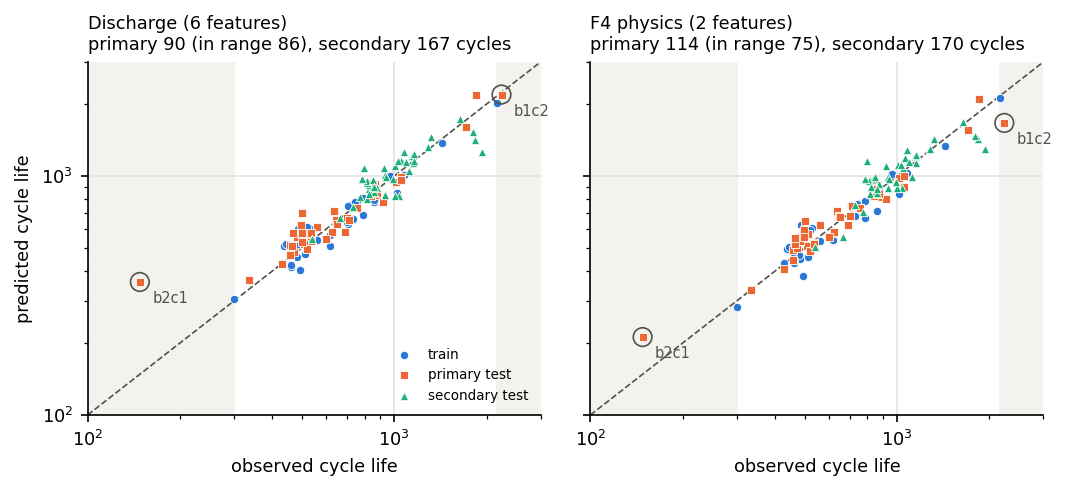

In [13]:
# paired bootstrap: difference in RMSE (A - B), identical in-range cells for all models
for key, b in E["bootstrap"].items():
    print(f"{key} ({b['n']} cells)")
    for pair, v in b.items():
        if "-" in pair:
            print(f"   {pair:20s} {v['rmse_diff']:+6.1f} cycles  95% CI {v['rmse_ci'][0]:+.0f} to {v['rmse_ci'][1]:+.0f}  "
                  f"(A better in {v['a_better_pct']:.0f}% of resamples)")
Image(str(ROOT / "report" / "figures" / "fig_p3_parity.png"), width=760)

**Reading it.** F4 (2 features) beats the full model (9) on both test sets, most clearly on the secondary batch where
the full model's batch-proxy features fail, and ties the discharge model (6) on the secondary set. On the primary set it
has the best % error but a higher RMSE than the discharge model, because it under-predicts `b1c2`, the cell that lives
longer than any training cell; it predicts the anomalous `b2c1` far better than any other model. With ~40 test cells,
differences of 10–20 cycles are within the bootstrap uncertainty: F4 is close to the best on both sets, not clearly the best.

## 8 · Caveats and what Phase 4 must test
1. **Selection optimism.** 19 candidates were screened on 41 cells; the training-CV comparison (§6) was optimistic:
   there F4 looked better than the discharge model, on the test sets (§7) it is not.
2. **b2 evidence is weak.** b2 lives span a narrow range (300–527); most within-batch evidence comes from b1.
3. **Overhang behaviour is batch-specific.** u1 rises later and more (median peak at cycle 81, only 20% of the
   rise by cycle 10); b3 rises least. The overhang feature may transfer poorly; if the contamination idea is right,
   u1's ΔQ understates its degradation (prediction to check in Phase 5).
4. **Rest time / temperature** remain hypotheses for the batch differences (Phase 5).

**F4 = [`margin_rate`, `overhang_after10`]**, implemented in `src/features.py`, tested in `tests/test_features.py`
(finite for all 163 cells; no data after cycle 100 used).